In [1]:

!pip install -q torch torchvision onnx onnxruntime fastapi uvicorn python-multipart matplotlib pillow requests


In [2]:

import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import os
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")


PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu
Selected device: cpu
GPU not available. Using CPU.


100%|██████████| 9.91M/9.91M [00:00<00:00, 37.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.12MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.8MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.92MB/s]


Training images: 60000
Testing images: 10000


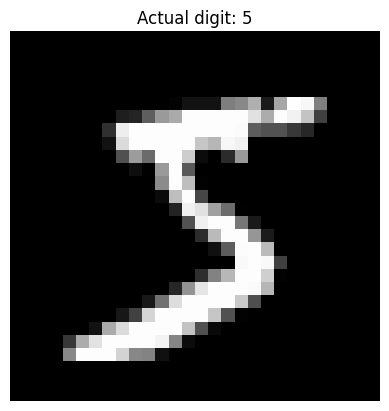

In [3]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()

train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_data, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_data, batch_size=64, shuffle=False
)

print("Training images:", len(train_data))
print("Testing images:", len(test_data))

image, label = train_data[0]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual digit: {label}")
plt.axis("off")
plt.show()


In [4]:

class VisionPortCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = VisionPortCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 3
train_losses = []
train_accuracies = []

for epoch in range(epochs):
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    avg_loss = running_loss / len(train_loader)
    accuracy = 100 * correct / total

    train_losses.append(avg_loss)
    train_accuracies.append(accuracy)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {avg_loss:.4f} | "
        f"Accuracy: {accuracy:.2f}%"
    )

print("Model training completed!")


Epoch 1/3 | Loss: 0.2456 | Accuracy: 92.48%
Epoch 2/3 | Loss: 0.0627 | Accuracy: 98.11%
Epoch 3/3 | Loss: 0.0454 | Accuracy: 98.53%
Model training completed!


Test Accuracy: 98.82%


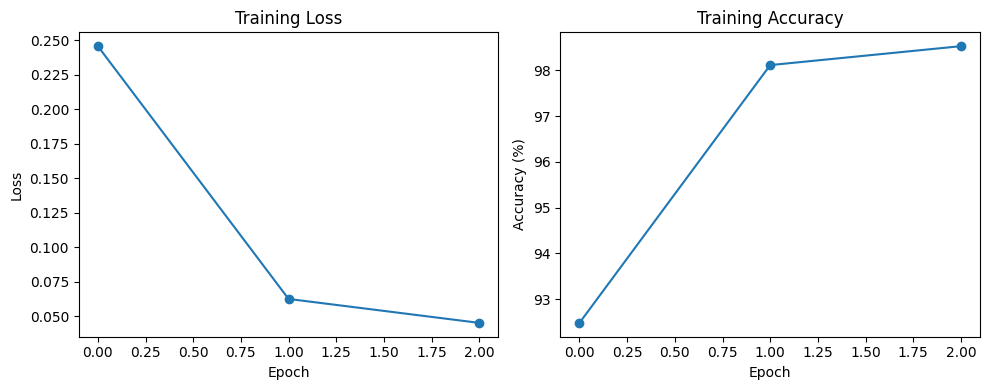

In [5]:

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, marker="o")
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, marker="o")
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.tight_layout()
plt.show()


In [18]:

# Save trained PyTorch model

torch.save({
    "model_state_dict": model.state_dict(),
    "test_accuracy": test_accuracy,
    "model_name": "VisionPortCNN"
}, "visionport_model.pth")

print("Model checkpoint saved successfully!")
print("File: visionport_model.pth")
print(f"Test accuracy: {test_accuracy:.2f}%")


Model checkpoint saved successfully!
File: visionport_model.pth
Test accuracy: 98.82%


In [6]:

model.eval()

dummy_input = torch.randn(1, 1, 28, 28).to(device)

onnx_path = "visionport_model.onnx"

torch.onnx.export(
    model,
    dummy_input,
    onnx_path,
    input_names=["input"],
    output_names=["output"],
    dynamic_axes={
        "input": {0: "batch_size"},
        "output": {0: "batch_size"}
    },
    opset_version=17,
    dynamo=False
)

print("ONNX model exported:", onnx_path)


ONNX model exported: visionport_model.onnx


/tmp/ipykernel_688/1320347475.py:7: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


In [7]:

import onnx
import onnxruntime as ort

onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)

print("ONNX model validation successful!")

session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

sample_image, actual_label = test_data[0]
input_array = sample_image.unsqueeze(0).numpy()

start = time.time()
result = session.run(
    ["output"],
    {"input": input_array}
)
onnx_time = (time.time() - start) * 1000

predicted_label = int(np.argmax(result[0]))

print("Actual digit:", actual_label)
print("Predicted digit:", predicted_label)
print(f"ONNX CPU inference time: {onnx_time:.2f} ms")


ONNX model validation successful!
Actual digit: 7
Predicted digit: 7
ONNX CPU inference time: 0.46 ms


In [8]:

from fastapi import FastAPI, UploadFile, File
from PIL import Image
import io
import uvicorn
import threading
import requests

app = FastAPI(title="VisionPort Digit Recognition API")

@app.get("/")
def home():
    return {
        "project": "VisionPort",
        "status": "Running",
        "model": "MNIST CNN with ONNX Runtime"
    }

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    image_bytes = await file.read()

    image = Image.open(io.BytesIO(image_bytes)).convert("L")
    image = image.resize((28, 28))

    image_array = np.array(image).astype("float32") / 255.0
    image_array = image_array.reshape(1, 1, 28, 28)

    prediction = session.run(
        ["output"],
        {"input": image_array}
    )[0]

    digit = int(np.argmax(prediction, axis=1)[0])

    return {
        "predicted_digit": digit,
        "confidence": float(
            torch.softmax(torch.tensor(prediction), dim=1)[0, digit]
        )
    }

def start_api():
    uvicorn.run(app, host="0.0.0.0", port=8000)

api_thread = threading.Thread(target=start_api, daemon=True)
api_thread.start()

time.sleep(3)

print("FastAPI server started!")
print("API address: http://127.0.0.1:8000")


INFO:     Started server process [688]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


FastAPI server started!
API address: http://127.0.0.1:8000


In [9]:

response = requests.get("http://127.0.0.1:8000/")

print("Status code:", response.status_code)
print("Response:", response.json())


INFO:     127.0.0.1:51606 - "GET / HTTP/1.1" 200 OK
Status code: 200
Response: {'project': 'VisionPort', 'status': 'Running', 'model': 'MNIST CNN with ONNX Runtime'}


In [10]:

from PIL import Image
import io

sample_image, actual_label = test_data[5]

image_for_api = (
    sample_image.squeeze().numpy() * 255
).astype("uint8")

buffer = io.BytesIO()
Image.fromarray(image_for_api).save(buffer, format="PNG")
buffer.seek(0)

response = requests.post(
    "http://127.0.0.1:8000/predict",
    files={"file": ("digit.png", buffer, "image/png")}
)

print("Actual digit:", actual_label)
print("API response:", response.json())


INFO:     127.0.0.1:35554 - "POST /predict HTTP/1.1" 200 OK
Actual digit: 1
API response: {'predicted_digit': 1, 'confidence': 0.999821126461029}


In [11]:

import os
import shutil

triton_model_dir = (
    "triton_model_repository/visionport/1"
)

os.makedirs(triton_model_dir, exist_ok=True)

shutil.copy(
    onnx_path,
    os.path.join(triton_model_dir, "model.onnx")
)

print("Triton model repository created!")
print("Model location:", triton_model_dir)


Triton model repository created!
Model location: triton_model_repository/visionport/1


In [12]:

config = """
name: "visionport"
platform: "onnxruntime_onnx"
max_batch_size: 8

input [
  {
    name: "input"
    data_type: TYPE_FP32
    dims: [ 1, 28, 28 ]
  }
]

output [
  {
    name: "output"
    data_type: TYPE_FP32
    dims: [ 10 ]
  }
]

instance_group [
  {
    kind: KIND_GPU
    count: 1
  }
]
"""

with open(
    "triton_model_repository/visionport/config.pbtxt",
    "w"
) as f:
    f.write(config)

print("Triton configuration created!")
print(config)


Triton configuration created!

name: "visionport"
platform: "onnxruntime_onnx"
max_batch_size: 8

input [
  {
    name: "input"
    data_type: TYPE_FP32
    dims: [ 1, 28, 28 ]
  }
]

output [
  {
    name: "output"
    data_type: TYPE_FP32
    dims: [ 10 ]
  }
]

instance_group [
  {
    kind: KIND_GPU
    count: 1
  }
]



In [13]:

import subprocess
import importlib.util

print("Checking TensorRT Python package...")

if importlib.util.find_spec("tensorrt"):
    import tensorrt as trt
    print("TensorRT available!")
    print("TensorRT version:", trt.__version__)
else:
    print("TensorRT Python package is not installed.")

print("\nChecking trtexec...")

try:
    result = subprocess.run(
        ["trtexec", "--version"],
        capture_output=True,
        text=True,
        timeout=15
    )
    print(result.stdout or result.stderr)
except (FileNotFoundError, subprocess.TimeoutExpired):
    print("trtexec is unavailable in this Colab runtime.")
    print("TensorRT engine creation requires a compatible NVIDIA environment.")


Checking TensorRT Python package...
TensorRT Python package is not installed.

Checking trtexec...
trtexec is unavailable in this Colab runtime.
TensorRT engine creation requires a compatible NVIDIA environment.


In [14]:

import subprocess
import os

if shutil.which("trtexec"):
    command = [
        "trtexec",
        f"--onnx={onnx_path}",
        "--saveEngine=visionport_model.engine"
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    print(result.stdout[-3000:])
    print(result.stderr[-1000:])

    if os.path.exists("visionport_model.engine"):
        print("TensorRT engine created successfully!")
    else:
        print("Engine creation failed. Check the TensorRT output.")
else:
    print("Skipping engine creation: trtexec is not available.")


Skipping engine creation: trtexec is not available.


In [15]:

sample_image, actual_label = test_data[10]
input_tensor = sample_image.unsqueeze(0).to(device)
input_numpy = sample_image.unsqueeze(0).numpy()

# PyTorch inference
model.eval()

with torch.no_grad():
    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.time()
    pytorch_output = model(input_tensor)

    if device.type == "cuda":
        torch.cuda.synchronize()

    pytorch_time = (time.time() - start) * 1000

# ONNX Runtime CPU inference
start = time.time()

onnx_output = session.run(
    ["output"],
    {"input": input_numpy}
)

onnx_cpu_time = (time.time() - start) * 1000

print("Actual digit:", actual_label)
print("PyTorch prediction:", pytorch_output.argmax(dim=1).item())
print("ONNX prediction:", int(np.argmax(onnx_output[0])))

print(f"PyTorch ({device}): {pytorch_time:.3f} ms")
print(f"ONNX Runtime CPU: {onnx_cpu_time:.3f} ms")


Actual digit: 0
PyTorch prediction: 0
ONNX prediction: 0
PyTorch (cpu): 3.410 ms
ONNX Runtime CPU: 0.706 ms


Average PyTorch inference: 0.801 ms
Average ONNX CPU inference: 0.243 ms


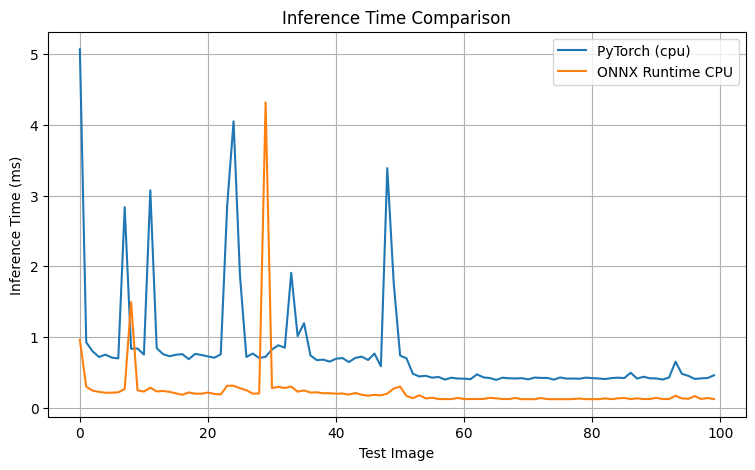

In [19]:

# Compare inference time over 100 test images

pytorch_times = []
onnx_times = []

model.eval()

for i in range(100):
    image, label = test_data[i]

    # PyTorch timing
    input_tensor = image.unsqueeze(0).to(device)

    with torch.no_grad():
        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()
        model(input_tensor)

        if device.type == "cuda":
            torch.cuda.synchronize()

        pytorch_times.append(
            (time.perf_counter() - start) * 1000
        )

    # ONNX CPU timing
    input_numpy = image.unsqueeze(0).numpy()

    start = time.perf_counter()
    session.run(["output"], {"input": input_numpy})

    onnx_times.append(
        (time.perf_counter() - start) * 1000
    )

print("Average PyTorch inference:",
      round(np.mean(pytorch_times), 3), "ms")

print("Average ONNX CPU inference:",
      round(np.mean(onnx_times), 3), "ms")

plt.figure(figsize=(9, 5))

plt.plot(pytorch_times, label=f"PyTorch ({device})")
plt.plot(onnx_times, label="ONNX Runtime CPU")

plt.title("Inference Time Comparison")
plt.xlabel("Test Image")
plt.ylabel("Inference Time (ms)")
plt.legend()
plt.grid(True)
plt.show()
